# 🎬 Cinemania — Film sharhlarini tuyg'u bo'yicha tasniflash
**Yakuniy amaliy vazifa:** IMDB sharhlari asosida **RNN** va **Transformer (DistilBERT)** modellarini qurish, o'qitish va taqqoslash.

> ⚙️ Tavsiya: `Runtime → Change runtime type → T4 GPU` (DistilBERT GPU'da bir necha daqiqada o'qiydi).

In [1]:
!pip -q install datasets openpyxl

import re, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset as TorchDataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Qurilma:', device)

Qurilma: cuda


## 1. Ma'lumotlarni tayyorlash va tahlil qilish
### 1.1. Ma'lumotlar to'plamini yuklash

In [2]:
!wget -q -nc https://github.com/laxmimerit/IMDB-Movie-Reviews-Large-Dataset-50k/raw/master/train.xlsx

data = pd.read_excel('train.xlsx')
print("Hajmi:", data.shape)
print("Ustunlar:", data.columns.tolist())
data.head()

Hajmi: (25000, 2)
Ustunlar: ['Reviews', 'Sentiment']


,Reviews,Sentiment
0,"When I first tuned in on this morning news, I ...",neg
1,"Mere thoughts of ""Going Overboard"" (aka ""Babes...",neg
2,Why does this movie fall WELL below standards?...,neg
3,Wow and I thought that any Steven Segal movie ...,neg
4,"The story is seen before, but that does'n matt...",neg


### 1.2. Ma'lumotlarni tozalash va o'zgartirish
Faylda ustunlar `Reviews` / `Sentiment`, qiymatlar esa `pos` / `neg` ko'rinishida — ularni `review` / `sentiment` va `positive` / `negative` ga keltiramiz.

In [3]:
# 1) Faqat review va sentiment ustunlarini qoldiramiz
data = data.rename(columns={'Reviews': 'review', 'Sentiment': 'sentiment'})[['review', 'sentiment']]
data['sentiment'] = data['sentiment'].replace({'pos': 'positive', 'neg': 'negative'})
print(data['sentiment'].value_counts(), '\n')

# 2) Har bir toifadan 1000 tadan tasodifiy namuna (random_state=101)
positive_df = data[data['sentiment'] == 'positive'].sample(n=1000, random_state=101)
negative_df = data[data['sentiment'] == 'negative'].sample(n=1000, random_state=101)

# 3) Birlashtirish va aralashtirish (frac=1)
df = pd.concat([positive_df, negative_df]).sample(frac=1, random_state=101).reset_index(drop=True)
df['label'] = (df['sentiment'] == 'positive').astype(int)   # positive=1, negative=0

print("Yangi DataFrame:", df.shape)
print(df['sentiment'].value_counts())
df.head()

sentiment
negative    12500
positive    12500
Name: count, dtype: int64 

Yangi DataFrame: (2000, 3)
sentiment
negative    1000
positive    1000
Name: count, dtype: int64


,review,sentiment,label
0,I honestly had somewhat high expectations when...,negative,0
1,"Level One, Horror.<br /><br />When I saw this ...",positive,1
2,Having seen the hot Eliza Dushku in the pretty...,negative,0
3,DEATHSTALKER is perfect for B-fantasy movie fa...,negative,0
4,This is an interesting left turn for Reel 13 I...,negative,0


count    2000.0
mean      235.1
std       180.1
min        10.0
25%       125.8
50%       178.0
75%       284.0
max      1601.0
Name: review, dtype: float64


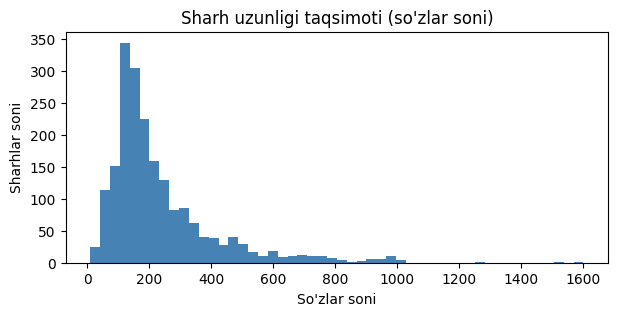

In [4]:
# Qisqa tahlil: sharhlar uzunligi (so'zlarda)
lengths_words = df['review'].str.split().str.len()
print(lengths_words.describe().round(1))

plt.figure(figsize=(7, 3))
plt.hist(lengths_words, bins=50, color='steelblue')
plt.title("Sharh uzunligi taqsimoti (so'zlar soni)")
plt.xlabel("So'zlar soni"); plt.ylabel('Sharhlar soni')
plt.show()

## 2. RNN modeli uchun ma'lumotlarni kodlash
### 2.1. Lug'at (vocabulary) yaratish

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<br\s*/?>', ' ', text)        # HTML <br /> teglarini olib tashlash
    text = re.sub(r"[^a-z0-9' ]", ' ', text)      # harf/raqamdan boshqa belgilarni olib tashlash
    return text

def tokenize(text):
    return clean_text(text).split()

# 1) Tokenizatsiya
df['tokens'] = df['review'].apply(tokenize)

# 2) So'zlar chastotasi
word_counts = Counter(token for tokens in df['tokens'] for token in tokens)
print("Noyob so'zlar soni:", len(word_counts))

# 3-4) Eng ko'p uchraydigan 4000 ta so'z + <pad>=0, <unk>=1
VOCAB_SIZE = 4000
vocab = {'<pad>': 0, '<unk>': 1}
for word, _ in word_counts.most_common(VOCAB_SIZE):
    vocab[word] = len(vocab)

print("Lug'at hajmi:", len(vocab))
print("Eng ko'p uchraydigan 10 so'z:", word_counts.most_common(10))

Noyob so'zlar soni: 27403
Lug'at hajmi: 4002
Eng ko'p uchraydigan 10 so'z: [('the', 27146), ('a', 13256), ('and', 13156), ('of', 11830), ('to', 10733), ('is', 8501), ('in', 7516), ('it', 6345), ('i', 6204), ('this', 6193)]


### 2.2. Matnni sonli ketma-ketlikka o'girish

In [6]:
def encode_review(text):
    return [vocab.get(token, vocab['<unk>']) for token in tokenize(text)]

df['encoded'] = df['review'].apply(encode_review)

print(df['review'][0][:200], '...')
print(df['encoded'][0][:30], '...')
df[['review', 'sentiment', 'encoded']].head()

I honestly had somewhat high expectations when I first began to watch this movie, but it turned out to be probably one of the most boring films I have ever seen!<br /><br />First of all, the pace is i ...
[10, 1204, 66, 631, 307, 1530, 51, 10, 75, 1853, 6, 103, 11, 17, 18, 9, 705, 44, 6, 26, 224, 27, 5, 2, 91, 359, 102, 10, 25, 118] ...


,review,sentiment,encoded
0,I honestly had somewhat high expectations when...,negative,"[10, 1204, 66, 631, 307, 1530, 51, 10, 75, 185..."
1,"Level One, Horror.<br /><br />When I saw this ...",positive,"[780, 27, 191, 51, 10, 207, 11, 19, 16, 2, 75,..."
2,Having seen the hot Eliza Dushku in the pretty...,negative,"[231, 108, 2, 878, 1, 1, 8, 2, 181, 49, 361, 4..."
3,DEATHSTALKER is perfect for B-fantasy movie fa...,negative,"[1, 7, 409, 16, 486, 905, 17, 512, 11, 1235, 2..."
4,This is an interesting left turn for Reel 13 I...,negative,"[11, 7, 32, 195, 326, 485, 16, 1, 1496, 1, 104..."


## 3. SentimentRNN modelini qurish va o'qitish
### 3.1. Model arxitekturasi
`Embedding(128) → RNN(256) → Linear → Sigmoid`. Turli uzunlikdagi sharhlar uchun `pack_padded_sequence` ishlatiladi — shunda RNN `<pad>` tokenlarini o'qimaydi va oxirgi yashirin holat haqiqiy oxirgi so'zdan olinadi.

In [7]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, output_dim=1, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, lengths):
        embedded = self.embedding(x)                                   # [B, T, 128]
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, hidden = self.rnn(packed)                                   # hidden: [1, B, 256]
        out = self.fc(hidden[-1])                                      # [B, 1]
        return self.sigmoid(out).squeeze(1)                            # [B] — ehtimollik

EMBEDDING_DIM, HIDDEN_DIM = 128, 256
rnn_model = SentimentRNN(len(vocab), EMBEDDING_DIM, HIDDEN_DIM).to(device)
print(rnn_model)
print("Parametrlar soni:", sum(p.numel() for p in rnn_model.parameters()))

SentimentRNN(
  (embedding): Embedding(4002, 128, padding_idx=0)
  (rnn): RNN(128, 256, batch_first=True)
  (fc): Linear(in_features=256, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parametrlar soni: 611329


### 3.2. Modelni sozlash va o'qitish
Adolatli taqqoslash uchun RNN ham Transformer bilan **aynan bir xil** train/test bo'linishida o'qitiladi va baholanadi (4.1-bo'limdagi kabi `seed=123`, test = 500 ta sharh).

In [8]:
# Train/test bo'linishi — 4.1-bo'limdagi bilan bir xil (seed=123)
rnn_splits = Dataset.from_pandas(df[['review', 'label', 'encoded']]).train_test_split(test_size=500, seed=123)
print(rnn_splits)

MAX_LEN = 256   # juda uzun sharhlarni qisqartiramiz (Transformer bilan bir xil)

class ReviewDataset(TorchDataset):
    def __init__(self, encoded, labels):
        self.seqs = [(seq[:MAX_LEN] or [vocab['<unk>']]) for seq in encoded]
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return torch.tensor(self.seqs[idx], dtype=torch.long), float(self.labels[idx])

def collate_fn(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    padded = pad_sequence(seqs, batch_first=True, padding_value=vocab['<pad>'])
    return padded, lengths, torch.tensor(labels, dtype=torch.float)

rnn_train_ds = ReviewDataset(rnn_splits['train']['encoded'], rnn_splits['train']['label'])
rnn_test_ds  = ReviewDataset(rnn_splits['test']['encoded'],  rnn_splits['test']['label'])

BATCH_SIZE = 32
train_loader = DataLoader(rnn_train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
test_loader  = DataLoader(rnn_test_ds,  batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(rnn_model.parameters(), lr=0.001)

DatasetDict({
    train: Dataset({
        features: ['review', 'label', 'encoded'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['review', 'label', 'encoded'],
        num_rows: 500
    })
})


In [9]:
def evaluate_rnn(model, loader):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, lengths, y in loader:
            x, y = x.to(device), y.to(device)
            probs = model(x, lengths)
            total_loss += criterion(probs, y).item() * len(y)
            correct += ((probs >= 0.5).float() == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n

EPOCHS = 10
rnn_history = []
for epoch in range(1, EPOCHS + 1):
    rnn_model.train()
    running_loss = 0.0
    for x, lengths, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        probs = rnn_model(x, lengths)
        loss = criterion(probs, y)
        loss.backward()
        nn.utils.clip_grad_norm_(rnn_model.parameters(), max_norm=1.0)   # RNN'da gradient portlashining oldini oladi
        optimizer.step()
        running_loss += loss.item() * len(y)

    train_loss = running_loss / len(rnn_train_ds)
    test_loss, test_acc = evaluate_rnn(rnn_model, test_loader)
    rnn_history.append({'epoch': epoch, 'train_loss': train_loss, 'test_loss': test_loss, 'test_acc': test_acc})
    print(f"Epoxa {epoch:2d}/{EPOCHS} | o'rtacha yo'qotish (train): {train_loss:.4f} "
          f"| test loss: {test_loss:.4f} | test accuracy: {test_acc:.3f}")

rnn_history = pd.DataFrame(rnn_history)

Epoxa  1/10 | o'rtacha yo'qotish (train): 0.7155 | test loss: 0.7036 | test accuracy: 0.528
Epoxa  2/10 | o'rtacha yo'qotish (train): 0.6219 | test loss: 0.7139 | test accuracy: 0.568
Epoxa  3/10 | o'rtacha yo'qotish (train): 0.5252 | test loss: 0.7858 | test accuracy: 0.564
Epoxa  4/10 | o'rtacha yo'qotish (train): 0.4471 | test loss: 0.8231 | test accuracy: 0.564
Epoxa  5/10 | o'rtacha yo'qotish (train): 0.3402 | test loss: 1.0543 | test accuracy: 0.576
Epoxa  6/10 | o'rtacha yo'qotish (train): 0.2163 | test loss: 1.2348 | test accuracy: 0.588
Epoxa  7/10 | o'rtacha yo'qotish (train): 0.1529 | test loss: 1.4071 | test accuracy: 0.552
Epoxa  8/10 | o'rtacha yo'qotish (train): 0.1086 | test loss: 1.5809 | test accuracy: 0.592
Epoxa  9/10 | o'rtacha yo'qotish (train): 0.0731 | test loss: 1.6914 | test accuracy: 0.586
Epoxa 10/10 | o'rtacha yo'qotish (train): 0.0505 | test loss: 1.6966 | test accuracy: 0.596


## 4. Transformer modeli uchun ma'lumotlarni tayyorlash
### 4.1. Dataset obyektini yaratish

> ⚠️ Topshiriqda train = 2500, test = 500 deyilgan, lekin 1.2-bo'limdan keyin jami **2000** ta sharh bor (1000 + 1000). Shuning uchun test = **500** ta saqlanib, qolgan **1500** tasi train uchun ishlatiladi.

In [10]:
hf_dataset = Dataset.from_pandas(df[['review', 'label']])
splits = hf_dataset.train_test_split(test_size=500, seed=123)
print(splits)

# RNN bilan aynan bir xil test to'plami ekanini tekshiramiz
print("Test to'plamlari bir xilmi:", splits['test']['review'] == rnn_splits['test']['review'])

DatasetDict({
    train: Dataset({
        features: ['review', 'label'],
        num_rows: 1500
    })
    test: Dataset({
        features: ['review', 'label'],
        num_rows: 500
    })
})
Test to'plamlari bir xilmi: True


### 4.2. Matnni tokenizatsiya qilish

In [11]:
MODEL_NAME = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    return tokenizer(examples['review'], padding='max_length', truncation=True, max_length=256)

tokenized_train = splits['train'].map(preprocess_function, batched=True, remove_columns=['review'])
tokenized_test  = splits['test'].map(preprocess_function, batched=True, remove_columns=['review'])
print(tokenized_train)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1500
})


## 5. Transformer modelini o'qitish va baholash
### 5.1. Modelni yuklash va sozlash

In [12]:
id2label = {0: 'negative', 1: 'positive'}
label2id = {'negative': 0, 'positive': 1}
tf_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': float((preds == labels).mean())}

training_args = TrainingArguments(
    output_dir='./distilbert-cinemania',
    num_train_epochs=3,
    logging_steps=100,
    eval_strategy='epoch',          # har epoxa oxirida test loss'ni ham ko'ramiz
    save_strategy='no',
    report_to='none',
    fp16=torch.cuda.is_available(),
    seed=SEED,
)

trainer = Trainer(
    model=tf_model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    compute_metrics=compute_metrics,
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### 5.2. Modelni o'qitish va baholash

In [13]:
train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy
1,0.492912,0.341284,0.870000
2,0.245351,0.565051,0.864000
3,0.072821,0.561539,0.876000


TrainOutput(global_step=564, training_loss=0.2437510574963076, metrics={'train_runtime': 43.3676, 'train_samples_per_second': 103.764, 'train_steps_per_second': 13.005, 'total_flos': 298051646976000.0, 'train_loss': 0.2437510574963076, 'epoch': 3.0})


In [14]:
eval_results = trainer.evaluate()
print(eval_results)
print(f"\neval_loss = {eval_results['eval_loss']:.4f} | eval_accuracy = {eval_results['eval_accuracy']:.3f}")

# Har 100 qadamdagi train loss
tf_logs = pd.DataFrame(trainer.state.log_history)
tf_train_logs = tf_logs.dropna(subset=['loss'])[['step', 'epoch', 'loss']]
tf_train_logs

Training Loss,Validation Loss,Epoch,Accuracy
0.072821,0.561539,3,0.876000


{'eval_loss': 0.5615386962890625, 'eval_accuracy': 0.876}

eval_loss = 0.5615 | eval_accuracy = 0.876


,step,epoch,loss
0,100,0.531915,0.492912
2,200,1.063830,0.350912
3,300,1.595745,0.245351
5,400,2.127660,0.154071
6,500,2.659574,0.072821


## 6. Ikkala modelni taqqoslash va xulosa
### 6.1. Bashorat funksiyalari

In [15]:
def predict_rnn(text):
    rnn_model.eval()
    ids = encode_review(text)[:MAX_LEN] or [vocab['<unk>']]
    x = torch.tensor([ids], dtype=torch.long).to(device)
    lengths = torch.tensor([len(ids)])
    with torch.no_grad():
        p_pos = rnn_model(x, lengths).item()
    return ('positive' if p_pos >= 0.5 else 'negative'), p_pos

def predict_transformer(text):
    tf_model.eval()
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=256).to(tf_model.device)
    with torch.no_grad():
        probs = torch.softmax(tf_model(**inputs).logits, dim=-1)[0]
    p_pos = probs[1].item()
    return ('positive' if p_pos >= 0.5 else 'negative'), p_pos

print(predict_rnn("This movie was absolutely wonderful, I loved it!"))
print(predict_transformer("This movie was absolutely wonderful, I loved it!"))

('positive', 0.5251902341842651)
('positive', 0.9978129863739014)


### 6.2. Yangi sharhlarda sinov
Ikkala model ham **ingliz tilidagi** IMDB sharhlarida o'qitilgan, shuning uchun sharhlar ingliz tiliga tarjima qilinib beriladi. Taqqoslash uchun asl o'zbekcha matnlar ham sinab ko'rilgan.

In [16]:
new_reviews = [
    ("a", "Bu filmni juda uzoq kutgandim, lekin umuman yoqmadi.",
          "I had been waiting for this movie for a very long time, but I didn't like it at all."),
    ("b", "Aktyorlar jamoasi ajoyib, syujet ham juda qiziqarli ekan.",
          "The cast is amazing, and the plot is also very interesting."),
    ("c", "Filmning vizual effektlari yaxshi, ammo hikoyasi zaif.",
          "The visual effects of the film are good, but the story is weak."),
]

rows = []
for key, uz, en in new_reviews:
    for lang, text in [('EN', en), ('UZ', uz)]:
        rnn_label, rnn_p = predict_rnn(text)
        tf_label, tf_p = predict_transformer(text)
        rows.append({'#': key, 'til': lang, 'sharh': text,
                     'RNN': f"{rnn_label} ({rnn_p:.2f})",
                     'Transformer': f"{tf_label} ({tf_p:.2f})"})
        print(f"{key}) [{lang}] {text}\n    RNN         -> {rnn_label:8s} (P(positive)={rnn_p:.2f})"
              f"\n    Transformer -> {tf_label:8s} (P(positive)={tf_p:.2f})\n")

predictions_df = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', 100)
predictions_df

a) [EN] I had been waiting for this movie for a very long time, but I didn't like it at all.
    RNN         -> negative (P(positive)=0.01)
    Transformer -> negative (P(positive)=0.00)

a) [UZ] Bu filmni juda uzoq kutgandim, lekin umuman yoqmadi.
    RNN         -> negative (P(positive)=0.31)
    Transformer -> positive (P(positive)=0.65)

b) [EN] The cast is amazing, and the plot is also very interesting.
    RNN         -> negative (P(positive)=0.04)
    Transformer -> positive (P(positive)=1.00)

b) [UZ] Aktyorlar jamoasi ajoyib, syujet ham juda qiziqarli ekan.
    RNN         -> negative (P(positive)=0.31)
    Transformer -> positive (P(positive)=0.84)

c) [EN] The visual effects of the film are good, but the story is weak.
    RNN         -> negative (P(positive)=0.06)
    Transformer -> negative (P(positive)=0.00)

c) [UZ] Filmning vizual effektlari yaxshi, ammo hikoyasi zaif.
    RNN         -> positive (P(positive)=0.53)
    Transformer -> positive (P(positive)=0.92)



,#,til,sharh,RNN,Transformer
0,a,EN,"I had been waiting for this movie for a very long time, but I didn't like it at all.",negative (0.01),negative (0.00)
1,a,UZ,"Bu filmni juda uzoq kutgandim, lekin umuman yoqmadi.",negative (0.31),positive (0.65)
2,b,EN,"The cast is amazing, and the plot is also very interesting.",negative (0.04),positive (1.00)
3,b,UZ,"Aktyorlar jamoasi ajoyib, syujet ham juda qiziqarli ekan.",negative (0.31),positive (0.84)
4,c,EN,"The visual effects of the film are good, but the story is weak.",negative (0.06),negative (0.00)
5,c,UZ,"Filmning vizual effektlari yaxshi, ammo hikoyasi zaif.",positive (0.53),positive (0.92)


,Model,Oxirgi train loss,Test (eval) loss,Test accuracy,Epoxalar
0,SentimentRNN,0.0505,1.6966,0.596,10
1,DistilBERT (Transformer),0.0728,0.5615,0.876,3


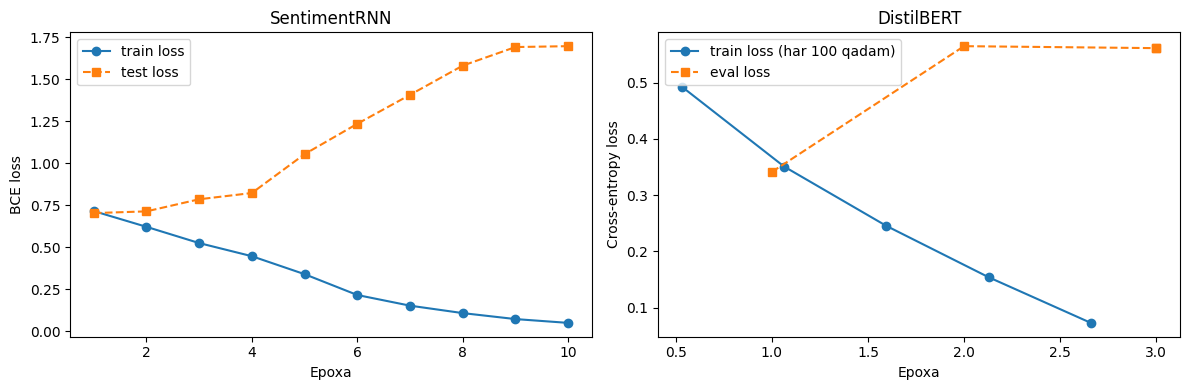

In [17]:
# Yakuniy taqqoslash jadvali
rnn_last = rnn_history.iloc[-1]
comparison = pd.DataFrame({
    'Model': ['SentimentRNN', 'DistilBERT (Transformer)'],
    "Oxirgi train loss": [rnn_last['train_loss'], tf_train_logs['loss'].iloc[-1]],
    'Test (eval) loss': [rnn_last['test_loss'], eval_results['eval_loss']],
    'Test accuracy': [rnn_last['test_acc'], eval_results['eval_accuracy']],
    'Epoxalar': [EPOCHS, 3],
}).round(4)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rnn_history['epoch'], rnn_history['train_loss'], 'o-', label='train loss')
axes[0].plot(rnn_history['epoch'], rnn_history['test_loss'], 's--', label='test loss')
axes[0].set_title('SentimentRNN'); axes[0].set_xlabel('Epoxa'); axes[0].set_ylabel('BCE loss'); axes[0].legend()

tf_eval_logs = tf_logs.dropna(subset=['eval_loss'])
axes[1].plot(tf_train_logs['epoch'], tf_train_logs['loss'], 'o-', label='train loss (har 100 qadam)')
axes[1].plot(tf_eval_logs['epoch'], tf_eval_logs['eval_loss'], 's--', label='eval loss')
axes[1].set_title('DistilBERT'); axes[1].set_xlabel('Epoxa'); axes[1].set_ylabel('Cross-entropy loss'); axes[1].legend()
plt.tight_layout(); plt.show()

### 6.3. Xulosa
Bu vazifa uchun Transformer modeli ancha yaxshiroq. Chunki u atigi 3 epoxada eval_loss = 0.56 va 87.6% aniqlikka erishdi. SentimentRNN esa 10 epoxadan keyin test loss 1.70 va 59.6% aniqlikdan qoldi. Transformer 3ala sharxni ham to'g'ri tasnifladi, chunki u oldindan katta matn korpusida o'qitilgan va uzun sharxlardagi kontekstni yaxshiroq tushunadi, RNN esa o'qitish sharxlarini yodlab olgan va yangi ijobiy sharxlarni ham salbiy deb topyapti.
